# 0. Exploración Inicial y Carga de Datos
En este notebook importamos los datos crudos (Raw Data) y validamos la calidad y la necesidad de aplicar transformaciones posteriores.

**Pregunta guía:** ¿qué es realmente una fila de este dataset y qué podemos corregir sin perder información relevante?

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")

# Los .py y data/ viven en la raíz del proyecto: si el notebook corre desde notebooks/, subimos un nivel
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
os.makedirs(os.path.join("output", "graficos"), exist_ok=True)

import numpy as np
import pandas as pd
from src.pipeline import cargar_datos_raw
from src import graficos as gr

pd.set_option("display.max_columns", 30)
df_raw = cargar_datos_raw()
print(f"Filas: {df_raw.shape[0]:,} | Columnas: {df_raw.shape[1]}")
df_raw.head()

[pipeline] Cargando raw data...
Filas: 114,000 | Columnas: 21


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


## 1. Estructura y tipos

In [2]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

In [3]:
df_raw.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,114000.0,56999.500,32909.110,0.000,28499.750,56999.500,85499.250,113999.000
popularity,114000.0,33.239,22.305,0.000,17.000,35.000,50.000,100.000
duration_ms,114000.0,228029.153,107297.713,0.000,174066.000,212906.000,261506.000,5237295.000
danceability,114000.0,0.567,0.174,0.000,0.456,0.580,0.695,0.985
energy,114000.0,0.641,0.252,0.000,0.472,0.685,0.854,1.000
key,114000.0,5.309,3.560,0.000,2.000,5.000,8.000,11.000
loudness,114000.0,-8.259,5.029,-49.531,-10.013,-7.004,-5.003,4.532
mode,114000.0,0.638,0.481,0.000,0.000,1.000,1.000,1.000
speechiness,114000.0,0.085,0.106,0.000,0.036,0.049,0.084,0.965
acousticness,114000.0,0.315,0.333,0.000,0.017,0.169,0.598,0.996


## 2. Calidad de los datos
Nulos, columnas sobrantes y valores que no tienen sentido físico (duración ≤ 0, tempo = 0, etc.).

In [4]:
nulos = df_raw.isna().sum()
print("Columnas con nulos:")
print(nulos[nulos > 0].to_string())
es_indice = np.array_equal(df_raw["Unnamed: 0"].values, np.arange(len(df_raw)))
print(f"\n'Unnamed: 0' es solo el índice del CSV original: {es_indice}")

Columnas con nulos:
artists       1
album_name    1
track_name    1

'Unnamed: 0' es solo el índice del CSV original: True


In [5]:
chequeos = {
    "duration_ms <= 0": (df_raw.duration_ms <= 0).sum(),
    "tempo == 0": (df_raw.tempo == 0).sum(),
    "time_signature == 0": (df_raw.time_signature == 0).sum(),
    "danceability == 0": (df_raw.danceability == 0).sum(),
    "popularity == 0": (df_raw.popularity == 0).sum(),
}
pd.Series(chequeos, name="filas").to_frame().assign(pct=lambda d: (d.filas / len(df_raw) * 100).round(2))

,filas,pct
duration_ms <= 0,1,0.00
tempo == 0,157,0.14
time_signature == 0,163,0.14
danceability == 0,157,0.14
popularity == 0,16020,14.05


**Decisiones de calidad:**
- **Nulos:** solo una fila, y solo en columnas de texto (`artists`, `album_name`, `track_name`). Se elimina: es una sola fila y no hay forma razonable de reconstruir el artista o el título.
- **`Unnamed: 0`:** coincide exactamente con el índice del CSV (`True` arriba), no describe la canción. Se descarta.
- **Valores en 0 (`tempo`, `time_signature`, `danceability`, `duration_ms`):** son el 0,14% de las filas o menos. Se mantienen: su efecto es despreciable y eliminarlos no cambiaría las conclusiones.
- **`popularity == 0`:** 16.020 filas (14,05%), demasiadas para ser errores sueltos. No se elimina aquí; si se concentra en ciertos géneros o artistas se revisa en el EDA.

## 3. Duplicados: ¿qué es realmente una fila?
Si `track_id` identifica una canción, ¿por qué hay más filas que canciones? Separamos los duplicados exactos de los que aparecen por otra razón.

In [6]:
cols = [c for c in df_raw.columns if c != "Unnamed: 0"]
resumen = pd.Series({
    "Filas totales": len(df_raw),
    "track_id únicos": df_raw.track_id.nunique(),
    "Filas extra por track_id repetido": df_raw.duplicated("track_id").sum(),
    "Filas completamente idénticas": df_raw.duplicated(subset=cols).sum(),
    "Filas extra por (artists, track_name) repetido": df_raw.duplicated(["artists", "track_name"]).sum(),
}, name="conteo")
resumen.to_frame()

,conteo
Filas totales,114000
track_id únicos,89741
Filas extra por track_id repetido,24259
Filas completamente idénticas,450
"Filas extra por (artists, track_name) repetido",32656


Canciones con más de un género: 16,299 (18.2% de las canciones únicas)
Máximo de géneros para una misma canción: 9


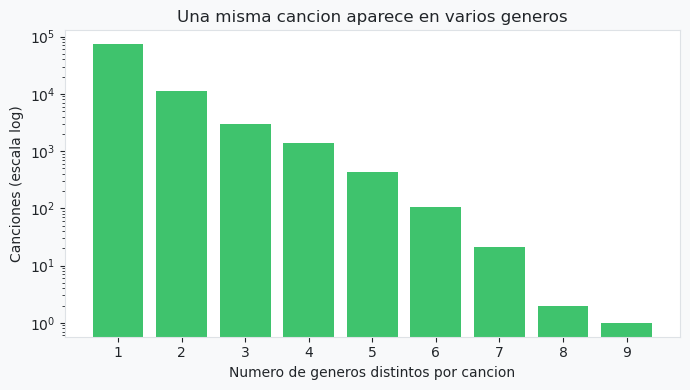

[graficos] Guardado: output\graficos\00_generos_por_cancion.png


In [7]:
gen_por_cancion = df_raw.groupby("track_id").track_genre.nunique()
dist = gen_por_cancion.value_counts().sort_index()
multi = (gen_por_cancion > 1)
print(f"Canciones con más de un género: {multi.sum():,} ({multi.mean()*100:.1f}% de las canciones únicas)")
print(f"Máximo de géneros para una misma canción: {gen_por_cancion.max()}")

gr.grafico_generos_por_cancion(dist)

**Decisión sobre duplicados:** hay 24.259 filas extra por `track_id` repetido, pero solo 450 son filas idénticas; el resto es la misma canción listada en otro género (18,2% de las canciones únicas, hasta 9 géneros). Por eso **no** se usa `drop_duplicates(keep="first")`, que dejaría un género arbitrario por canción: se agrupa por `track_id` y se conservan todos los géneros (multi-hot en el EDA). Además, 32.656 filas repiten artista + título con distinto `track_id` (otro álbum o versión): esa combinación (`song_key`) se usa como clave del split para que versiones de una misma canción no queden en train y test a la vez.

In [8]:
pop_dist = df_raw.groupby("track_id").popularity.nunique()
inconsistentes = pop_dist[pop_dist > 1]
print(f"Canciones con popularidad distinta entre sus copias: {len(inconsistentes)}")
ejemplo = df_raw[df_raw.track_id == inconsistentes.index[0]]
ejemplo[["track_name", "artists", "track_genre", "popularity"]]

Canciones con popularidad distinta entre sus copias: 720


,track_name,artists,track_genre,popularity
55776,Amake Amar Moto Thakte Dao,Anupam Roy,indian,47
56324,Amake Amar Moto Thakte Dao,Anupam Roy,indie-pop,47
57529,Amake Amar Moto Thakte Dao,Anupam Roy,indie,47
65813,Amake Amar Moto Thakte Dao,Anupam Roy,k-pop,47
99268,Amake Amar Moto Thakte Dao,Anupam Roy,singer-songwriter,46
102269,Amake Amar Moto Thakte Dao,Anupam Roy,songwriter,46


**Decisión:** en 720 canciones la popularidad no es la misma en todas sus copias, aunque la diferencia es pequeña (en el ejemplo, 46 frente a 47). Se usa la **popularidad máxima** entre copias: evita que el orden del archivo decida la etiqueta.

## 4. Variable objetivo (vista preliminar)
El *hit* se define como popularidad ≥ P80. Revisamos cómo cambia el umbral según cómo se trate la duplicación.

In [9]:
p80_raw = df_raw.popularity.quantile(0.80)
p80_dedup = df_raw.groupby("track_id").popularity.max().quantile(0.80)
print(f"P80 sobre filas crudas (con repetidas): {p80_raw}")
print(f"P80 sobre canciones únicas (popularidad máxima): {p80_dedup}")
df_raw.popularity.quantile([0.5, 0.75, 0.8, 0.9, 0.95]).to_frame("popularity")

P80 sobre filas crudas (con repetidas): 54.0
P80 sobre canciones únicas (popularidad máxima): 52.0


,popularity
0.50,35.0
0.75,50.0
0.80,54.0
0.90,63.0
0.95,69.0


**Decisión:** el P80 baja de 54 (filas crudas) a 52 (canciones únicas), porque las canciones repetidas en varios géneros pesan más de una vez en las filas crudas. Por eso el umbral se calcula una sola vez, después de deduplicar y **solo con train**, para que test no influya en la definición de `hit`.

## 5. Género: ¿cómo se construyó el dataset?

In [10]:
conteo = df_raw.track_genre.value_counts()
print(f"Géneros distintos: {conteo.nunique() and len(conteo)}")
print(f"Todos los géneros tienen exactamente {conteo.iloc[0]:,} filas: {bool((conteo == conteo.iloc[0]).all())}")
conteo.describe().to_frame("filas por género").T

Géneros distintos: 114
Todos los géneros tienen exactamente 1,000 filas: True


,count,mean,std,min,25%,50%,75%,max
filas por género,114.0,1000.0,0.0,1000.0,1000.0,1000.0,1000.0,1000.0


**Decisión:** el dataset se construyó con exactamente 1.000 filas por cada uno de los 114 géneros, así que no refleja cuántas canciones de cada género hay en Spotify. No se corrige (no hay datos del mercado real): las tasas de hit por género reflejan el muestreo y se declara como limitación en el EDA y el informe.

## Conclusiones y decisiones de preprocesamiento

| Hallazgo | Decisión |
|---|---|
| Nulos mínimos y solo en texto (`artists`, `album_name`, `track_name`) | Se elimina esa fila; no afecta a las variables numéricas |
| `Unnamed: 0` es solo un índice | Se descarta |
| Una fila **no** es una canción: hay más filas que `track_id` únicos | Una fila por `track_id`, agregando en vez de descartar |
| Solo una fracción pequeña de las repetidas son duplicados exactos; el resto es la misma canción **en otro género** | **No** usar `drop_duplicates(keep="first")`: se conserva todos los géneros (multi-hot) y la popularidad máxima |
| Varias canciones difieren en popularidad entre copias | Popularidad = máximo entre copias |
| Misma canción con `track_id` distinto (otro álbum/versión) | Split agrupado por artista + título para evitar fuga entre train y test |
| El P80 cambia según cómo se trate la duplicación | Se calcula una sola vez, **solo con train**, tras deduplicar |
| El dataset tiene la misma cantidad de filas por género | La tasa de hits por género refleja el muestreo, no el mercado real (se discute en el EDA) |
| Valores en 0 en `tempo`, `time_signature`, `danceability` y `duration_ms` (≤ 0,14% de las filas) | Se mantienen; efecto despreciable |
| Hay un bloque de `popularity == 0` | No se elimina automáticamente; se revisa en el EDA |